# Evaluación downstream: síntomas BDI-II (eRisk 2024) y riesgo en comunidades trans (T-Risk)

Este cuaderno compara `citiusLTL/DisorBERT` frente a cada variante adaptada por MLM detectada en `../03_adaptacion_mlm/artefactos/` (`DysphorBERT` y ablaciones) en tres experimentos complementarios:

1. **Experimento A (eRisk 2024, 21 síntomas BDI-II):** control de olvido clínico tras la adaptación de dominio.
2. **Experimento B1 (transferencia cero-shot a `gold_1400.csv` y `gold_bdi21.csv`):** evaluación directa de los detectores BDI-II sobre el discurso trans usando `max(p01..p21)` como score binario.
3. **Experimento B2 (validación cruzada 5-fold en `gold_1400.csv`):** ajuste fino supervisado con partición estratificada y agrupada por autor.
4. **Análisis cualitativo y exportación:** casos reales con jerga trans, figuras a 200 dpi y tablas LaTeX `booktabs` en `resultados/`.

Ejecuta el cuaderno con directorio de trabajo `04_evaluacion_downstream/`.

## 0. Importaciones, configuración y utilidades compartidas

In [1]:
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import (
    AutoConfig,
    AutoModel,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)

In [2]:
# Rutas principales (CWD = 04_evaluacion_downstream/)
ERISK_CSV = Path("../01_datos_reddit/datos/eRisk_2024_dataset_majority.csv")
GOLD_CSV = Path("../02_dataset_gold/datos/gold_1400.csv")
ESTRATOS_JSON = Path("../02_dataset_gold/datos/estratos.json")
GOLD_BDI21_CSV = Path("../02_dataset_gold/datos/gold_bdi21.csv")
LEXICO_TRANS_TXT = Path("../03_adaptacion_mlm/artefactos/lexico_trans.txt")
MLM_ARTEFACTOS = Path("../03_adaptacion_mlm/artefactos")
RESULTADOS = Path("resultados")
RESULTADOS.mkdir(parents=True, exist_ok=True)

# Descubrimiento dinámico de modelos
MODELOS = {"DisorBERT_base": "citiusLTL/DisorBERT"}
for carpeta in sorted(MLM_ARTEFACTOS.glob("disorbert_trans_*")):
    modelo_dir = carpeta / "modelo_final"
    if (modelo_dir / "model.safetensors").exists():
        clave = carpeta.name.removeprefix("disorbert_trans_")
        MODELOS[clave] = str(modelo_dir)

print(f"Modelos detectados ({len(MODELOS)}):")
for nombre, ruta in MODELOS.items():
    print(f"  - {nombre}: {ruta}")

# Hiperparámetros
SEED = 42
REENTRENAR = False
BF16 = True
EPOCHS_ERISK = 4
BATCH_ERISK = 64
MAX_LEN_ERISK = 128
LR_FT = 2e-5
EPOCHS_GOLD = 4
BATCH_GOLD = 16
MAX_LEN_GOLD = 256
N_FOLDS = 5
N_BOOT = 1000

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_BF16 = BF16 and DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()
print(f"Dispositivo: {DEVICE} | bf16: {USE_BF16}")

# Lista canónica BDI-II (1..21 en el orden exacto de eRisk 2024 y gold_bdi21.csv)
BDI_21 = [
    (1, "Sadness", "Tristeza"),
    (2, "Pessimism", "Pesimismo"),
    (3, "Past Failure", "Fracaso pasado"),
    (4, "Loss of Pleasure", "Pérdida de placer"),
    (5, "Guilty Feelings", "Sentimientos de culpa"),
    (6, "Punishment Feelings", "Sentimientos de castigo"),
    (7, "Self-Dislike", "Rechazo hacia sí mismo"),
    (8, "Self-Criticalness", "Autocrítica"),
    (9, "Suicidal Thoughts or Wishes", "Pensamientos suicidas"),
    (10, "Crying", "Llanto"),
    (11, "Agitation", "Agitación"),
    (12, "Loss of Interest", "Pérdida de interés"),
    (13, "Indecisiveness", "Indecisión"),
    (14, "Worthlessness", "Inutilidad o falta de valor"),
    (15, "Loss of Energy", "Pérdida de energía"),
    (16, "Changes in Sleeping Pattern", "Cambios en el sueño"),
    (17, "Irritability", "Irritabilidad"),
    (18, "Changes in Appetite", "Cambios en el apetito"),
    (19, "Concentration Difficulty", "Dificultad de concentración"),
    (20, "Tiredness or Fatigue", "Cansancio o fatiga"),
    (21, "Loss of Interest in Sex", "Pérdida de interés en el sexo"),
]
COLS_S = [f"s{n:02d}" for n, _, _ in BDI_21]
COLS_P = [f"p{n:02d}" for n, _, _ in BDI_21]

Modelos detectados (4):
  - DisorBERT_base: citiusLTL/DisorBERT
  - depresion+trans: ../03_adaptacion_mlm/artefactos/disorbert_trans_depresion+trans/modelo_final
  - depresion+trans_pdep50_autor: ../03_adaptacion_mlm/artefactos/disorbert_trans_depresion+trans_pdep50_autor/modelo_final
  - ninguno_autor: ../03_adaptacion_mlm/artefactos/disorbert_trans_ninguno_autor/modelo_final
Dispositivo: cuda | bf16: True


In [3]:
def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def combinar_texto(df):
    titulo = df["titulo"].fillna("").astype(str).str.strip()
    cuerpo = df["texto"].fillna("").astype(str).str.strip()
    return (titulo + "\n\n" + cuerpo).str.strip().tolist()


class DatasetTextos(Dataset):
    def __init__(self, textos, labels=None, masks=None):
        self.textos = list(textos)
        self.labels = labels
        self.masks = masks

    def __len__(self):
        return len(self.textos)

    def __getitem__(self, idx):
        item = {"texto": self.textos[idx]}
        if self.labels is not None:
            item["labels"] = self.labels[idx]
        if self.masks is not None:
            item["masks"] = self.masks[idx]
        return item


def crear_dataloader(tokenizer, textos, max_len, batch_size, shuffle=False, labels=None, masks=None):
    ds = DatasetTextos(textos, labels=labels, masks=masks)

    def collate(lote):
        enc = tokenizer(
            [x["texto"] for x in lote],
            truncation=True,
            max_length=max_len,
            padding=True,
            return_tensors="pt",
        )
        if labels is not None:
            arr_y = np.asarray([x["labels"] for x in lote])
            dtype_y = torch.long if arr_y.ndim == 1 else torch.float32
            enc["labels"] = torch.tensor(arr_y, dtype=dtype_y)
        if masks is not None:
            enc["masks"] = torch.tensor(np.asarray([x["masks"] for x in lote]), dtype=torch.float32)
        return enc

    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=collate)


def evaluar_bdi21(probs, labels, masks):
    por_sintoma = []
    for j, (num, en, es) in enumerate(BDI_21):
        valido = masks[:, j] == 1
        y_j = labels[valido, j].astype(int)
        p_j = probs[valido, j]
        n_pos = int(y_j.sum())
        f1 = float(f1_score(y_j, (p_j >= 0.5).astype(int), zero_division=0)) if len(y_j) else float("nan")
        pr_auc = float(average_precision_score(y_j, p_j)) if n_pos > 0 else float("nan")
        roc_auc = float(roc_auc_score(y_j, p_j)) if 0 < n_pos < len(y_j) else float("nan")
        por_sintoma.append({
            "num": num,
            "sintoma": en,
            "sintoma_es": es,
            "n_eval": int(valido.sum()),
            "n_pos": n_pos,
            "f1": f1,
            "pr_auc": pr_auc,
            "roc_auc": roc_auc,
        })
    activos = masks == 1
    return {
        "macro_f1": float(np.nanmean([r["f1"] for r in por_sintoma])),
        "micro_f1": float(f1_score(labels[activos].astype(int), (probs[activos] >= 0.5).astype(int), zero_division=0)),
        "macro_pr_auc": float(np.nanmean([r["pr_auc"] for r in por_sintoma])),
        "macro_roc_auc": float(np.nanmean([r["roc_auc"] for r in por_sintoma])),
        "por_sintoma": por_sintoma,
    }


def cargar_pesos_estrato(df):
    if not ESTRATOS_JSON.exists():
        return np.ones(len(df), dtype=float)
    poblacion = json.loads(ESTRATOS_JSON.read_text(encoding="utf-8")).get("estratos", {})
    clave = df["subreddit"].fillna("").astype(str).str.strip().str.lower() + "|" + df["banda"].fillna("").astype(str).str.strip()
    n_estrato = clave.value_counts().to_dict()
    return clave.map(lambda k: poblacion[k] / n_estrato[k] if k in poblacion else 1.0).to_numpy(dtype=float)


def metricas_binarias(y_true, y_prob, sample_weight=None, umbral=0.5):
    y_true = np.asarray(y_true, dtype=int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= umbral).astype(int)
    return {
        "pr_auc": float(average_precision_score(y_true, y_prob, sample_weight=sample_weight)),
        "roc_auc": float(roc_auc_score(y_true, y_prob, sample_weight=sample_weight)),
        "f1": float(f1_score(y_true, y_pred, sample_weight=sample_weight, zero_division=0)),
        "precision": float(precision_score(y_true, y_pred, sample_weight=sample_weight, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, sample_weight=sample_weight, zero_division=0)),
    }


def bootstrap_pareado(y_true, probs_a, probs_base=None, sample_weight=None, n_boot=N_BOOT, seed=SEED):
    y_true = np.asarray(y_true, dtype=int)
    probs_a = np.asarray(probs_a, dtype=float)
    w = None if sample_weight is None else np.asarray(sample_weight, dtype=float)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals_pr, vals_f1, diffs_pr, diffs_f1 = [], [], [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        yb = y_true[idx]
        if yb.min() == yb.max():
            continue
        wb = None if w is None else w[idx]
        pr_a = average_precision_score(yb, probs_a[idx], sample_weight=wb)
        f1_a = f1_score(yb, (probs_a[idx] >= 0.5).astype(int), sample_weight=wb, zero_division=0)
        vals_pr.append(pr_a)
        vals_f1.append(f1_a)
        if probs_base is not None:
            pb = np.asarray(probs_base, dtype=float)[idx]
            diffs_pr.append(pr_a - average_precision_score(yb, pb, sample_weight=wb))
            diffs_f1.append(f1_a - f1_score(yb, (pb >= 0.5).astype(int), sample_weight=wb, zero_division=0))

    lo_pr, hi_pr = np.percentile(vals_pr, [2.5, 97.5])
    lo_f1, hi_f1 = np.percentile(vals_f1, [2.5, 97.5])
    out = {
        "pr_ci_lo": float(lo_pr),
        "pr_ci_hi": float(hi_pr),
        "f1_ci_lo": float(lo_f1),
        "f1_ci_hi": float(hi_f1),
        "p_pr_vs_base": float("nan"),
        "p_f1_vs_base": float("nan"),
    }
    if probs_base is not None and diffs_pr:
        dpr = np.asarray(diffs_pr)
        df1 = np.asarray(diffs_f1)
        out["p_pr_vs_base"] = float(min(1.0, 2.0 * min((dpr <= 0).mean(), (dpr >= 0).mean())))
        out["p_f1_vs_base"] = float(min(1.0, 2.0 * min((df1 <= 0).mean(), (df1 >= 0).mean())))
    return out

## 1. Experimento A: 21 síntomas BDI-II en eRisk 2024 (control de olvido clínico)

Agrupamos `eRisk_2024_dataset_majority.csv` por `text` único en vectores binarios `labels` (21 síntomas) y `mask` (síntomas anotados para ese texto). La partición 70/15/15 se realiza por `user_prefix` (`docid.split("_")[0]`) para garantizar cero fuga de usuarios y de textos entre entrenamiento, validación y prueba.

In [4]:
erisk_raw = pd.read_csv(ERISK_CSV)
erisk_raw = erisk_raw[erisk_raw["text"].notna()].copy()
erisk_raw["text"] = erisk_raw["text"].astype(str).str.strip()
erisk_raw = erisk_raw[erisk_raw["text"] != ""].copy()
erisk_raw["user_prefix"] = erisk_raw["docid"].astype(str).str.split("_").str[0]

registros = {}
for row in erisk_raw.itertuples(index=False):
    txt = row.text
    if txt not in registros:
        registros[txt] = {
            "text": txt,
            "user_prefix": row.user_prefix,
            "labels": np.zeros(21, dtype=np.float32),
            "mask": np.zeros(21, dtype=np.float32),
        }
    q = int(row.query) - 1
    registros[txt]["mask"][q] = 1.0
    if int(row.rel) >= 1:
        registros[txt]["labels"][q] = 1.0

df_erisk = pd.DataFrame(registros.values())
usuarios = sorted(df_erisk["user_prefix"].unique())
random.Random(SEED).shuffle(usuarios)
n_u = len(usuarios)
c1, c2 = int(0.70 * n_u), int(0.85 * n_u)
u_tr, u_va, u_te = set(usuarios[:c1]), set(usuarios[c1:c2]), set(usuarios[c2:])

erisk_splits = {
    "train": df_erisk[df_erisk["user_prefix"].isin(u_tr)].reset_index(drop=True),
    "val": df_erisk[df_erisk["user_prefix"].isin(u_va)].reset_index(drop=True),
    "test": df_erisk[df_erisk["user_prefix"].isin(u_te)].reset_index(drop=True),
}

# Comprobación estricta de cero fuga de usuarios y de textos
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert set(erisk_splits[a]["user_prefix"]).isdisjoint(erisk_splits[b]["user_prefix"]), f"Fuga usuario {a}/{b}"
    assert set(erisk_splits[a]["text"]).isdisjoint(erisk_splits[b]["text"]), f"Fuga texto {a}/{b}"

for nombre_sp, sp in erisk_splits.items():
    m_sum = int(np.stack(sp["mask"].values).sum())
    y_sum = int(np.stack(sp["labels"].values).sum())
    print(f"eRisk {nombre_sp:<5}: {len(sp):>5,} textos · {sp['user_prefix'].nunique():>5,} usuarios · "
          f"{m_sum:>5,} anotaciones ({y_sum:,} positivas)")

eRisk train: 7,510 textos · 6,860 usuarios · 9,470 anotaciones (4,087 positivas)
eRisk val  : 1,602 textos · 1,470 usuarios · 2,045 anotaciones (863 positivas)
eRisk test : 1,621 textos · 1,471 usuarios · 2,066 anotaciones (887 positivas)


In [5]:
class ClasificadorBDI21(nn.Module):
    def __init__(self, ruta_modelo):
        super().__init__()
        cfg = AutoConfig.from_pretrained(ruta_modelo)
        self.encoder = AutoModel.from_pretrained(ruta_modelo, config=cfg)
        self.drop = nn.Dropout(0.1)
        self.head = nn.Linear(cfg.hidden_size, 21)

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        return self.head(self.drop(out.last_hidden_state[:, 0]))


def predecir_bdi21(model, dl):
    model.eval()
    probs_list = []
    with torch.no_grad():
        for batch in dl:
            with torch.amp.autocast("cuda", dtype=torch.bfloat16, enabled=USE_BF16):
                logits = model(
                    batch["input_ids"].to(DEVICE),
                    batch["attention_mask"].to(DEVICE),
                )
            probs_list.append(torch.sigmoid(logits).float().cpu().numpy())
    return np.vstack(probs_list)


def entrenar_o_cargar_erisk(nombre, ruta_modelo):
    out_dir = RESULTADOS / nombre
    out_dir.mkdir(parents=True, exist_ok=True)
    ckpt = out_dir / "erisk_bdi21_best.pt"
    preds_npz = out_dir / "erisk_test_preds.npz"
    metrics_json = out_dir / "erisk_metrics.json"

    if not REENTRENAR and ckpt.exists() and preds_npz.exists() and metrics_json.exists():
        print(f"[{nombre}] Cargando caché eRisk desde {out_dir}")
        return json.loads(metrics_json.read_text(encoding="utf-8")), dict(np.load(preds_npz))

    t0 = time.time()
    fijar_semilla(SEED)
    tok = AutoTokenizer.from_pretrained(ruta_modelo)

    y_tr = np.stack(erisk_splits["train"]["labels"].values)
    m_tr = np.stack(erisk_splits["train"]["mask"].values)
    y_va = np.stack(erisk_splits["val"]["labels"].values)
    m_va = np.stack(erisk_splits["val"]["mask"].values)
    y_te = np.stack(erisk_splits["test"]["labels"].values)
    m_te = np.stack(erisk_splits["test"]["mask"].values)

    dl_tr = crear_dataloader(tok, erisk_splits["train"]["text"].tolist(), MAX_LEN_ERISK, BATCH_ERISK, True, y_tr, m_tr)
    dl_va = crear_dataloader(tok, erisk_splits["val"]["text"].tolist(), MAX_LEN_ERISK, BATCH_ERISK, False)
    dl_te = crear_dataloader(tok, erisk_splits["test"]["text"].tolist(), MAX_LEN_ERISK, BATCH_ERISK, False)

    model = ClasificadorBDI21(ruta_modelo).to(DEVICE)
    if REENTRENAR or not ckpt.exists():
        opt = torch.optim.AdamW(model.parameters(), lr=LR_FT, weight_decay=0.01)
        total_steps = len(dl_tr) * EPOCHS_ERISK
        sched = get_linear_schedule_with_warmup(opt, math.ceil(0.1 * total_steps), total_steps)
        criterio = nn.BCEWithLogitsLoss(reduction="none")
        mejor_val = -1.0

        for ep in range(1, EPOCHS_ERISK + 1):
            model.train()
            pbar = tqdm(dl_tr, desc=f"{nombre} eRisk ep {ep}/{EPOCHS_ERISK}", leave=False)
            for batch in pbar:
                opt.zero_grad()
                with torch.amp.autocast("cuda", dtype=torch.bfloat16, enabled=USE_BF16):
                    logits = model(batch["input_ids"].to(DEVICE), batch["attention_mask"].to(DEVICE))
                    loss_mat = criterio(logits, batch["labels"].to(DEVICE))
                    masks_b = batch["masks"].to(DEVICE)
                    loss = (loss_mat * masks_b).sum() / masks_b.sum().clamp(min=1.0)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
                sched.step()

            val_probs = predecir_bdi21(model, dl_va)
            val_pr = evaluar_bdi21(val_probs, y_va, m_va)["macro_pr_auc"]
            print(f"  [{nombre}] época {ep}: val Macro PR-AUC = {val_pr:.4f}")
            if val_pr > mejor_val:
                mejor_val = val_pr
                torch.save(model.state_dict(), ckpt)

    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    test_probs = predecir_bdi21(model, dl_te)
    met = evaluar_bdi21(test_probs, y_te, m_te)
    met["modelo"] = nombre
    met["segundos"] = round(time.time() - t0, 1)

    np.savez(preds_npz, probs=test_probs, labels=y_te, masks=m_te)
    metrics_json.write_text(json.dumps(met, indent=2, ensure_ascii=False), encoding="utf-8")
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return met, {"probs": test_probs, "labels": y_te, "masks": m_te}


res_erisk = {}
preds_erisk = {}
for nombre, ruta in MODELOS.items():
    res_erisk[nombre], preds_erisk[nombre] = entrenar_o_cargar_erisk(nombre, ruta)

df_res_a = pd.DataFrame([
    {
        "modelo": k,
        "macro_f1": v["macro_f1"],
        "micro_f1": v["micro_f1"],
        "macro_pr_auc": v["macro_pr_auc"],
        "macro_roc_auc": v["macro_roc_auc"],
    }
    for k, v in res_erisk.items()
])
df_res_a.to_csv(RESULTADOS / "erisk_resumen.csv", index=False)
print("\nResumen Experimento A (eRisk 2024 test):")
print(df_res_a.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

mejor_a = df_res_a.sort_values("macro_pr_auc", ascending=False).iloc[0]["modelo"]
print(f"\nDesglose por síntoma BDI-II ({mejor_a}):")
print(pd.DataFrame(res_erisk[mejor_a]["por_sintoma"])[["num", "sintoma", "n_eval", "n_pos", "f1", "pr_auc", "roc_auc"]].to_string(index=False, float_format=lambda x: f"{x:.3f}"))

[DisorBERT_base] Cargando caché eRisk desde resultados/DisorBERT_base
[depresion+trans] Cargando caché eRisk desde resultados/depresion+trans
[depresion+trans_pdep50_autor] Cargando caché eRisk desde resultados/depresion+trans_pdep50_autor
[ninguno_autor] Cargando caché eRisk desde resultados/ninguno_autor

Resumen Experimento A (eRisk 2024 test):
                      modelo  macro_f1  micro_f1  macro_pr_auc  macro_roc_auc
              DisorBERT_base    0.8773    0.8819        0.9486         0.9637
             depresion+trans    0.8899    0.8951        0.9548         0.9662
depresion+trans_pdep50_autor    0.8877    0.8920        0.9518         0.9650
               ninguno_autor    0.8843    0.8892        0.9492         0.9660

Desglose por síntoma BDI-II (depresion+trans):
 num                     sintoma  n_eval  n_pos    f1  pr_auc  roc_auc
   1                     Sadness      96     56 0.912   0.968    0.958
   2                   Pessimism      91     43 0.829   0.930    0.933

## 2. Experimento B1: Transferencia cero-shot (21 síntomas → gold trans T-Risk)

Evaluamos los clasificadores `erisk_bdi21_best.pt` directamente sobre `gold_1400.csv` sin entrenar con ninguna etiqueta del dominio trans (`score = max(p01..p21)`). Si existen filas revisadas en `gold_bdi21.csv`, evaluamos también las 21 probabilidades por síntoma.

In [6]:
df_gold_all = pd.read_csv(GOLD_CSV, dtype={"id": str})
df_gold_all["id"] = df_gold_all["id"].astype(str)
df_gold_all["y"] = pd.to_numeric(df_gold_all["gold"], errors="coerce")
df_gold_b1 = df_gold_all[df_gold_all["y"].isin([0, 1])].copy()
df_gold_b1["y"] = df_gold_b1["y"].astype(int)

res_b1 = None
preds_b1_eval = {}
probs_b1_all = {}

if len(df_gold_b1) < 20 or df_gold_b1["y"].nunique() < 2:
    print(f"Aviso B1: gold_1400.csv tiene {len(df_gold_b1)} etiquetas humanas 0/1 "
          f"(clases={df_gold_b1['y'].nunique()}). Se omite Experimento B1.")
else:
    textos_all = combinar_texto(df_gold_all)
    for nombre, ruta in MODELOS.items():
        out_dir = RESULTADOS / nombre
        ckpt = out_dir / "erisk_bdi21_best.pt"
        cache_pq = out_dir / "gold1400_bdi21_probs.parquet"

        if not REENTRENAR and cache_pq.exists():
            df_p = pd.read_parquet(cache_pq)
            df_p["id"] = df_p["id"].astype(str)
        else:
            tok = AutoTokenizer.from_pretrained(ruta)
            dl = crear_dataloader(tok, textos_all, MAX_LEN_GOLD, BATCH_GOLD, False)
            model = ClasificadorBDI21(ruta).to(DEVICE)
            model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
            probs_21 = predecir_bdi21(model, dl)
            df_p = pd.DataFrame(probs_21, columns=COLS_P)
            df_p.insert(0, "id", df_gold_all["id"].values)
            df_p["score_max"] = probs_21.max(axis=1)
            df_p.to_parquet(cache_pq, index=False)
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        probs_b1_all[nombre] = df_p
        m_eval = df_gold_b1[["id", "subreddit", "banda", "y"]].merge(df_p[["id", "score_max"]], on="id", how="inner")
        preds_b1_eval[nombre] = m_eval

    base_b1 = preds_b1_eval["DisorBERT_base"]["score_max"].to_numpy() if "DisorBERT_base" in preds_b1_eval else None
    filas_b1 = []
    for nombre, m_eval in preds_b1_eval.items():
        y_true = m_eval["y"].to_numpy()
        y_prob = m_eval["score_max"].to_numpy()
        pesos_b1 = cargar_pesos_estrato(m_eval)
        m_crudo = metricas_binarias(y_true, y_prob)
        m_pond = metricas_binarias(y_true, y_prob, sample_weight=pesos_b1)
        boot = bootstrap_pareado(
            y_true,
            y_prob,
            probs_base=None if nombre == "DisorBERT_base" else base_b1,
            sample_weight=pesos_b1,
        )
        filas_b1.append({
            "modelo": nombre,
            "n": len(y_true),
            "muestra_pr_auc": m_crudo["pr_auc"],
            "muestra_roc_auc": m_crudo["roc_auc"],
            "muestra_f1": m_crudo["f1"],
            "pond_pr_auc": m_pond["pr_auc"],
            "pond_roc_auc": m_pond["roc_auc"],
            "pond_f1": m_pond["f1"],
            "pond_precision": m_pond["precision"],
            "pond_recall": m_pond["recall"],
            **boot,
        })
    res_b1 = pd.DataFrame(filas_b1)
    res_b1.to_csv(RESULTADOS / "b1_resumen.csv", index=False)
    print(f"Resumen Experimento B1 cero-shot (n={len(df_gold_b1):,}):")
    print(res_b1[["modelo", "muestra_pr_auc", "muestra_f1", "pond_pr_auc", "pond_roc_auc", "pond_f1", "pr_ci_lo", "pr_ci_hi", "p_pr_vs_base"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Resumen Experimento B1 cero-shot (n=1,400):
                      modelo  muestra_pr_auc  muestra_f1  pond_pr_auc  pond_roc_auc  pond_f1  pr_ci_lo  pr_ci_hi  p_pr_vs_base
              DisorBERT_base          0.2875      0.1801       0.3998        0.7219   0.2422    0.3150    0.4974           NaN
             depresion+trans          0.3283      0.1400       0.4493        0.7567   0.1826    0.3570    0.5454        0.0600
depresion+trans_pdep50_autor          0.3295      0.1608       0.4530        0.7734   0.2189    0.3606    0.5569        0.0280
               ninguno_autor          0.3228      0.2194       0.4683        0.7844   0.3141    0.3796    0.5679        0.0080


In [7]:
res_b1_sint = None
if not GOLD_BDI21_CSV.exists():
    print(f"Aviso B1-síntomas: no existe {GOLD_BDI21_CSV}. Se omite sub-experimento.")
else:
    df_gb21 = pd.read_csv(GOLD_BDI21_CSV, dtype=str).fillna("")
    df_gb21 = df_gb21[df_gb21["revisado"].str.strip() == "1"].copy()
    if df_gb21.empty:
        print("Aviso B1-síntomas: gold_bdi21.csv no tiene filas con revisado == '1'. Se omite sub-experimento.")
    else:
        y_b21 = df_gb21[COLS_S].apply(pd.to_numeric, errors="coerce").fillna(0).to_numpy(dtype=np.float32)
        m_b21 = np.ones_like(y_b21, dtype=np.float32)
        textos_b21 = combinar_texto(df_gb21)
        filas_s = []
        for nombre, ruta in MODELOS.items():
            if nombre in probs_b1_all:
                df_p = probs_b1_all[nombre]
                merged = df_gb21[["id"]].merge(df_p[["id"] + COLS_P], on="id", how="left")
                if merged[COLS_P].notna().all().all():
                    p_b21 = merged[COLS_P].to_numpy(dtype=np.float32)
                else:
                    p_b21 = None
            else:
                p_b21 = None
            if p_b21 is None:
                tok = AutoTokenizer.from_pretrained(ruta)
                dl = crear_dataloader(tok, textos_b21, MAX_LEN_GOLD, BATCH_GOLD, False)
                model = ClasificadorBDI21(ruta).to(DEVICE)
                model.load_state_dict(torch.load(RESULTADOS / nombre / "erisk_bdi21_best.pt", map_location=DEVICE, weights_only=True))
                p_b21 = predecir_bdi21(model, dl)
                del model
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

            met_s = evaluar_bdi21(p_b21, y_b21, m_b21)
            filas_s.append({
                "modelo": nombre,
                "n": len(df_gb21),
                "macro_f1": met_s["macro_f1"],
                "micro_f1": met_s["micro_f1"],
                "macro_pr_auc": met_s["macro_pr_auc"],
                "macro_roc_auc": met_s["macro_roc_auc"],
            })
        res_b1_sint = pd.DataFrame(filas_s)
        res_b1_sint.to_csv(RESULTADOS / "b1_sintomas_resumen.csv", index=False)
        print(f"Resumen B1-síntomas (n={len(df_gb21):,} revisados):")
        print(res_b1_sint.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Resumen B1-síntomas (n=180 revisados):
                      modelo   n  macro_f1  micro_f1  macro_pr_auc  macro_roc_auc
              DisorBERT_base 180    0.0906    0.0832        0.1826         0.5735
             depresion+trans 180    0.0544    0.0575        0.2072         0.6375
depresion+trans_pdep50_autor 180    0.0537    0.0569        0.1989         0.6178
               ninguno_autor 180    0.0853    0.1055        0.2024         0.6025


## 3. Experimento B2: Validación cruzada 5-fold agrupada por autor en `gold_1400.csv`

Entrenamos `AutoModelForSequenceClassification(num_labels=2)` en validación cruzada estratificada y agrupada por `author_hash` (cuando falta, usamos `anon_{id}`), evitando que publicaciones de la misma cuenta aparezcan en entrenamiento y validación del mismo fold. Las predicciones fuera de muestra (`cv_oof_preds.csv`) se guardan por fold para reanudar sin pérdida.

In [8]:
df_gold_b2 = df_gold_b1.copy()
n_neg = int((df_gold_b2["y"] == 0).sum()) if not df_gold_b2.empty else 0
n_pos = int((df_gold_b2["y"] == 1).sum()) if not df_gold_b2.empty else 0

res_b2 = None
preds_b2_eval = {}

if len(df_gold_b2) < 50 or n_neg < 10 or n_pos < 10:
    print(f"Aviso B2: se requieren >=50 etiquetas humanas 0/1 y >=10 por clase "
          f"(actual: total={len(df_gold_b2)}, neg={n_neg}, pos={n_pos}). Se omite Experimento B2.")
else:
    df_gold_b2 = df_gold_b2.reset_index(drop=True)
    grupos = df_gold_b2["author_hash"].fillna("").astype(str).str.strip()
    grupos = grupos.where(grupos != "", "anon_" + df_gold_b2["id"].astype(str))
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    df_gold_b2["fold"] = -1
    for f, (_, idx_va) in enumerate(sgkf.split(df_gold_b2, df_gold_b2["y"], grupos)):
        df_gold_b2.loc[idx_va, "fold"] = f
    textos_b2 = combinar_texto(df_gold_b2)

    for nombre, ruta in MODELOS.items():
        oof_csv = RESULTADOS / nombre / "cv_oof_preds.csv"
        (RESULTADOS / nombre).mkdir(parents=True, exist_ok=True)

        if not REENTRENAR and oof_csv.exists():
            df_oof = pd.read_csv(oof_csv, dtype={"id": str})
            df_oof = df_oof.merge(df_gold_b2[["id", "fold"]], on=["id", "fold"], how="inner")
        else:
            df_oof = pd.DataFrame(columns=["id", "fold", "y_true", "prob_pos"])

        folds_hechos = set(df_oof["fold"].unique()) if len(df_oof) == len(df_gold_b2) else set()
        if len(df_oof) > 0 and len(df_oof) < len(df_gold_b2):
            conteos_f = df_oof.groupby("fold").size().to_dict()
            esperados_f = df_gold_b2.groupby("fold").size().to_dict()
            folds_hechos = {f for f, n_esp in esperados_f.items() if conteos_f.get(f, 0) == n_esp}

        if len(folds_hechos) == N_FOLDS:
            print(f"[{nombre}] Cargando caché OOF 5-fold desde {oof_csv}")
        else:
            tok = AutoTokenizer.from_pretrained(ruta)
            for f in range(N_FOLDS):
                if f in folds_hechos:
                    continue
                fijar_semilla(SEED + f)
                idx_tr = np.where(df_gold_b2["fold"] != f)[0]
                idx_va = np.where(df_gold_b2["fold"] == f)[0]

                dl_tr = crear_dataloader(
                    tok,
                    [textos_b2[i] for i in idx_tr],
                    MAX_LEN_GOLD,
                    BATCH_GOLD,
                    True,
                    labels=df_gold_b2["y"].iloc[idx_tr].to_numpy(),
                )
                dl_va = crear_dataloader(tok, [textos_b2[i] for i in idx_va], MAX_LEN_GOLD, BATCH_GOLD, False)

                model = AutoModelForSequenceClassification.from_pretrained(ruta, num_labels=2).to(DEVICE)
                opt = torch.optim.AdamW(model.parameters(), lr=LR_FT, weight_decay=0.01)
                total_steps = len(dl_tr) * EPOCHS_GOLD
                sched = get_linear_schedule_with_warmup(opt, math.ceil(0.1 * total_steps), total_steps)

                mejor_pr = -1.0
                mejor_probs = None
                y_va = df_gold_b2["y"].iloc[idx_va].to_numpy()

                for ep in range(1, EPOCHS_GOLD + 1):
                    model.train()
                    for batch in tqdm(dl_tr, desc=f"{nombre} fold {f+1}/{N_FOLDS} ep {ep}", leave=False):
                        opt.zero_grad()
                        with torch.amp.autocast("cuda", dtype=torch.bfloat16, enabled=USE_BF16):
                            out = model(
                                input_ids=batch["input_ids"].to(DEVICE),
                                attention_mask=batch["attention_mask"].to(DEVICE),
                                labels=batch["labels"].to(DEVICE),
                            )
                        out.loss.backward()
                        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                        opt.step()
                        sched.step()

                    model.eval()
                    va_probs = []
                    with torch.no_grad():
                        for batch in dl_va:
                            with torch.amp.autocast("cuda", dtype=torch.bfloat16, enabled=USE_BF16):
                                logits = model(
                                    input_ids=batch["input_ids"].to(DEVICE),
                                    attention_mask=batch["attention_mask"].to(DEVICE),
                                ).logits
                            va_probs.append(torch.softmax(logits, dim=-1)[:, 1].float().cpu().numpy())
                    va_probs = np.concatenate(va_probs)
                    pr_f = average_precision_score(y_va, va_probs)
                    if pr_f > mejor_pr:
                        mejor_pr = pr_f
                        mejor_probs = va_probs

                df_fold = pd.DataFrame({
                    "id": df_gold_b2["id"].iloc[idx_va].values,
                    "fold": f,
                    "y_true": y_va,
                    "prob_pos": mejor_probs,
                })
                df_oof = pd.concat([df_oof[df_oof["fold"] != f], df_fold], ignore_index=True)
                df_oof.to_csv(oof_csv, index=False)
                del model
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

        preds_b2_eval[nombre] = df_gold_b2[["id", "subreddit", "banda", "y"]].merge(
            df_oof[["id", "prob_pos"]], on="id", how="inner"
        )

    base_b2 = preds_b2_eval["DisorBERT_base"]["prob_pos"].to_numpy() if "DisorBERT_base" in preds_b2_eval else None
    filas_b2 = []
    for nombre, m_eval in preds_b2_eval.items():
        y_true = m_eval["y"].to_numpy()
        y_prob = m_eval["prob_pos"].to_numpy()
        pesos_b2 = cargar_pesos_estrato(m_eval)
        m_crudo = metricas_binarias(y_true, y_prob)
        m_pond = metricas_binarias(y_true, y_prob, sample_weight=pesos_b2)
        boot = bootstrap_pareado(
            y_true,
            y_prob,
            probs_base=None if nombre == "DisorBERT_base" else base_b2,
            sample_weight=pesos_b2,
        )
        filas_b2.append({
            "modelo": nombre,
            "n": len(y_true),
            "muestra_pr_auc": m_crudo["pr_auc"],
            "muestra_roc_auc": m_crudo["roc_auc"],
            "muestra_f1": m_crudo["f1"],
            "pond_pr_auc": m_pond["pr_auc"],
            "pond_roc_auc": m_pond["roc_auc"],
            "pond_f1": m_pond["f1"],
            "pond_precision": m_pond["precision"],
            "pond_recall": m_pond["recall"],
            **boot,
        })
    res_b2 = pd.DataFrame(filas_b2)
    res_b2.to_csv(RESULTADOS / "b2_resumen.csv", index=False)
    print(f"Resumen Experimento B2 5-fold CV (n={len(df_gold_b2):,}):")
    print(res_b2[["modelo", "muestra_pr_auc", "muestra_f1", "pond_pr_auc", "pond_roc_auc", "pond_f1", "pr_ci_lo", "pr_ci_hi", "p_pr_vs_base"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: citiusLTL/DisorBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were 

DisorBERT_base fold 1/5 ep 1:   0%|          | 0/71 [00:00<?, ?it/s]

DisorBERT_base fold 1/5 ep 2:   0%|          | 0/71 [00:00<?, ?it/s]

DisorBERT_base fold 1/5 ep 3:   0%|          | 0/71 [00:00<?, ?it/s]

DisorBERT_base fold 1/5 ep 4:   0%|          | 0/71 [00:00<?, ?it/s]

... (96 outputs left out)

ninguno_autor fold 5/5 ep 2:   0%|          | 0/70 [00:00<?, ?it/s]

ninguno_autor fold 5/5 ep 3:   0%|          | 0/70 [00:00<?, ?it/s]

ninguno_autor fold 5/5 ep 4:   0%|          | 0/70 [00:00<?, ?it/s]

Resumen Experimento B2 5-fold CV (n=1,400):
                      modelo  muestra_pr_auc  muestra_f1  pond_pr_auc  pond_roc_auc  pond_f1  pr_ci_lo  pr_ci_hi  p_pr_vs_base
              DisorBERT_base          0.5785      0.5886       0.7109        0.8956   0.6835    0.6170    0.7951           NaN
             depresion+trans          0.6682      0.6469       0.8013        0.9342   0.7475    0.7332    0.8618        0.0000
depresion+trans_pdep50_autor          0.6514      0.6304       0.7762        0.9202   0.7199    0.7013    0.8420        0.0480
               ninguno_autor          0.6573      0.6361       0.7919        0.9301   0.7345    0.7206    0.8545        0.0000


## 4. Análisis cualitativo de jerga trans y exportación a LaTeX

Inspeccionamos publicaciones con vocabulario de `lexico_trans.txt` donde `DisorBERT_base` se equivoca y el mejor modelo adaptado acierta (junto con sus 3 síntomas BDI-II más probables), generamos las gráficas de resumen y exportamos tablas LaTeX `booktabs`.

In [9]:
adaptados = [m for m in MODELOS if m != "DisorBERT_base"]
res_ref = res_b2 if res_b2 is not None else res_b1
preds_ref = preds_b2_eval if res_b2 is not None else preds_b1_eval
col_prob_ref = "prob_pos" if res_b2 is not None else "score_max"

if res_ref is None or not adaptados or "DisorBERT_base" not in preds_ref:
    print("Sin predicciones binarias comparables (B1/B2) para análisis cualitativo de jerga trans.")
else:
    sub_adapt = res_ref[res_ref["modelo"].isin(adaptados)]
    mejor_adapt = sub_adapt.sort_values("pond_pr_auc", ascending=False).iloc[0]["modelo"]
    terminos_trans = (
        {ln.strip().lower() for ln in LEXICO_TRANS_TXT.read_text(encoding="utf-8").splitlines() if ln.strip()}
        if LEXICO_TRANS_TXT.exists()
        else set()
    )

    df_base_p = preds_ref["DisorBERT_base"][["id", "y", col_prob_ref]].rename(columns={col_prob_ref: "p_base"})
    df_best_p = preds_ref[mejor_adapt][["id", col_prob_ref]].rename(columns={col_prob_ref: "p_best"})
    casos = df_gold_all[["id", "subreddit", "titulo", "texto"]].merge(df_base_p, on="id").merge(df_best_p, on="id")
    casos["texto_full"] = combinar_texto(casos)

    if mejor_adapt in probs_b1_all:
        casos = casos.merge(probs_b1_all[mejor_adapt][["id"] + COLS_P], on="id", how="left")

    acierto_best = (casos["p_best"] >= 0.5).astype(int) == casos["y"]
    error_base = (casos["p_base"] >= 0.5).astype(int) != casos["y"]
    casos = casos[acierto_best & error_base].copy()

    def detectar_jerga(txt):
        palabras = {w.strip(".,!?;:\"'()[]{}") for w in txt.lower().split()}
        return sorted(palabras & terminos_trans)

    casos["jerga"] = casos["texto_full"].map(detectar_jerga)
    casos = casos[casos["jerga"].map(len) > 0].copy()
    casos["margen"] = (casos["p_best"] - casos["p_base"]).abs()
    casos = casos.sort_values("margen", ascending=False).head(5)

    print(f"Casos con jerga trans donde DisorBERT_base falla y {mejor_adapt} acierta ({len(casos)} mostrados):")
    for row in casos.itertuples(index=False):
        top3 = ""
        if hasattr(row, "p01"):
            scores = [(BDI_21[i][2], getattr(row, COLS_P[i])) for i in range(21)]
            scores.sort(key=lambda x: x[1], reverse=True)
            top3 = " | Top-3 BDI-II: " + ", ".join(f"{s} ({v:.2f})" for s, v in scores[:3])
        snippet = row.texto_full.replace("\n", " ")[:260]
        print(f"- [{row.id}] r/{row.subreddit} | y={row.y} | p_base={row.p_base:.3f} -> p_best={row.p_best:.3f} "
              f"| jerga={row.jerga[:5]}{top3}\n  \"{snippet}...\"")

Casos con jerga trans donde DisorBERT_base falla y depresion+trans acierta (5 mostrados):
- [117rbep] r/asktransgender | y=1 | p_base=0.096 -> p_best=0.945 | jerga=['agab', 'closeted'] | Top-3 BDI-II: Agitación (0.16), Tristeza (0.14), Sentimientos de castigo (0.12)
  "How to explain why my wife's opinion is transphobic?  My(nb27) wife(f27) has some potentially transphobic thoughts that I've been struggling to explain why they are problematic.   She has the idea that most transgender people have a mental illness(depression/a..."
- [1ntwtj6] r/transmasc | y=1 | p_base=0.034 -> p_best=0.840 | jerga=['detransitioning'] | Top-3 BDI-II: Agitación (0.22), Cansancio o fatiga (0.21), Tristeza (0.20)
  "Does this count as detransitioning?  I’m genuinely just really tired of getting up every day, doing makeup to feel masculine, buying clothing that’s uncomfortable on me and acting in ways that get me isolated from all of my girl-friends just because of my masc..."
- [1be9mfq] r/trans | y=1 | p_b

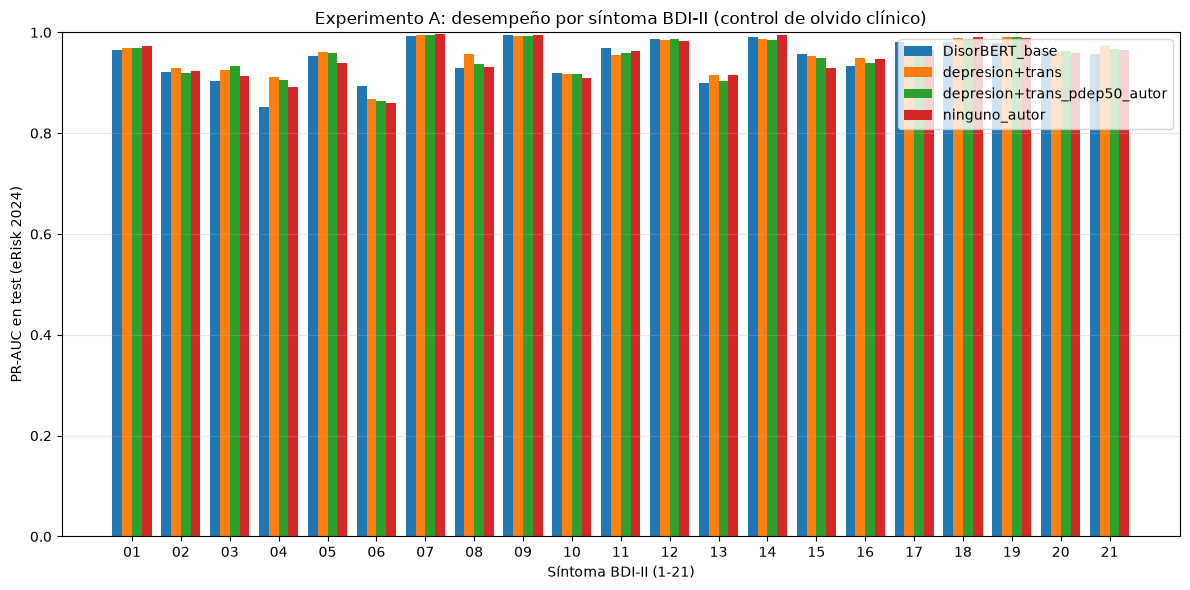

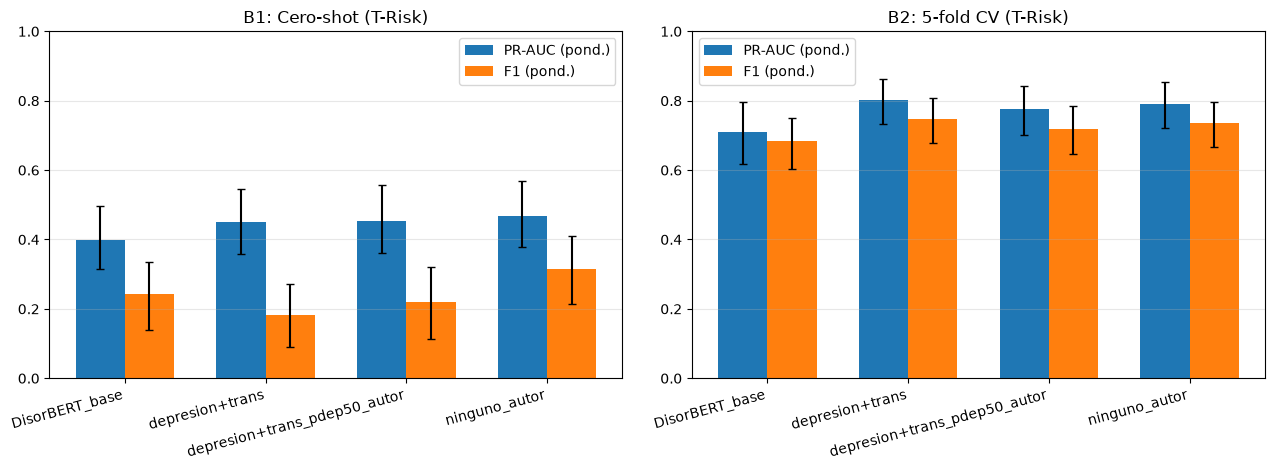

In [10]:
# Figura 1: Experimento A (eRisk 2024 por síntoma BDI-II)
if res_erisk:
    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(BDI_21))
    ancho = 0.8 / max(1, len(res_erisk))
    for i, (nombre, met) in enumerate(res_erisk.items()):
        vals = [r["pr_auc"] for r in met["por_sintoma"]]
        ax.bar(x + (i - (len(res_erisk) - 1) / 2) * ancho, vals, width=ancho, label=nombre)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{n:02d}" for n, _, _ in BDI_21])
    ax.set_xlabel("Síntoma BDI-II (1-21)")
    ax.set_ylabel("PR-AUC en test (eRisk 2024)")
    ax.set_title("Experimento A: desempeño por síntoma BDI-II (control de olvido clínico)")
    ax.set_ylim(0, 1.0)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTADOS / "fig_erisk_por_sintoma.png", dpi=200)
    plt.show()

# Figura 2: Comparación B1 / B2 en gold trans (métricas reponderadas)
paneles = [(t, df) for t, df in [("B1: Cero-shot (T-Risk)", res_b1), ("B2: 5-fold CV (T-Risk)", res_b2)] if df is not None]
if paneles:
    fig, axes = plt.subplots(1, len(paneles), figsize=(6.5 * len(paneles), 4.8), squeeze=False)
    for col_idx, (titulo, df_m) in enumerate(paneles):
        ax = axes[0, col_idx]
        x = np.arange(len(df_m))
        w = 0.35
        err_pr = np.vstack([
            np.clip(df_m["pond_pr_auc"] - df_m["pr_ci_lo"], 0, None),
            np.clip(df_m["pr_ci_hi"] - df_m["pond_pr_auc"], 0, None),
        ])
        err_f1 = np.vstack([
            np.clip(df_m["pond_f1"] - df_m["f1_ci_lo"], 0, None),
            np.clip(df_m["f1_ci_hi"] - df_m["pond_f1"], 0, None),
        ])
        ax.bar(x - w / 2, df_m["pond_pr_auc"], width=w, yerr=err_pr, capsize=3, label="PR-AUC (pond.)")
        ax.bar(x + w / 2, df_m["pond_f1"], width=w, yerr=err_f1, capsize=3, label="F1 (pond.)")
        ax.set_xticks(x)
        ax.set_xticklabels(df_m["modelo"], rotation=15, ha="right")
        ax.set_ylim(0, 1.0)
        ax.set_title(titulo)
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTADOS / "fig_trisk_comparacion.png", dpi=200)
    plt.show()

In [11]:
def escapar_tex(texto):
    return str(texto).replace("_", r"\_")


def guardar_tabla_booktabs(df, ruta, caption, label):
    cols = list(df.columns)
    alineacion = "l" + "r" * (len(cols) - 1)
    lineas = [
        r"\begin{table}[htbp]",
        r"\centering",
        f"\\caption{{{caption}}}",
        f"\\label{{{label}}}",
        f"\\begin{{tabular}}{{{alineacion}}}",
        r"\toprule",
        " & ".join(escapar_tex(c) for c in cols) + r" \\",
        r"\midrule",
    ]
    for _, row in df.iterrows():
        celdas = [escapar_tex(row[c]) for c in cols]
        lineas.append(" & ".join(celdas) + r" \\")
    lineas.extend([r"\bottomrule", r"\end{tabular}", r"\end{table}"])
    ruta.write_text("\n".join(lineas) + "\n", encoding="utf-8")
    print(f"Exportada tabla LaTeX: {ruta}")


if res_erisk:
    t_a = df_res_a.copy()
    for c in ["macro_f1", "micro_f1", "macro_pr_auc", "macro_roc_auc"]:
        t_a[c] = t_a[c].map(lambda v: f"{v:.3f}")
    t_a.columns = ["Modelo", "Macro F1", "Micro F1", "Macro PR-AUC", "Macro ROC-AUC"]
    guardar_tabla_booktabs(
        t_a,
        RESULTADOS / "tabla_erisk_bdi21.tex",
        "Resultados en eRisk 2024 (21 síntomas BDI-II).",
        "tab:erisk_bdi21",
    )

filas_bin = []
for exp_nombre, df_m in [("B1 (cero-shot)", res_b1), ("B2 (5-fold CV)", res_b2)]:
    if df_m is None:
        continue
    for _, r in df_m.iterrows():
        p_txt = "--" if np.isnan(r["p_pr_vs_base"]) else f"{r['p_pr_vs_base']:.3f}"
        filas_bin.append({
            "Experimento": exp_nombre,
            "Modelo": r["modelo"],
            "PR-AUC (muestra)": f"{r['muestra_pr_auc']:.3f}",
            "PR-AUC (pond.)": f"{r['pond_pr_auc']:.3f} [{r['pr_ci_lo']:.3f}, {r['pr_ci_hi']:.3f}]",
            "ROC-AUC (pond.)": f"{r['pond_roc_auc']:.3f}",
            "F1 (pond.)": f"{r['pond_f1']:.3f}",
            "P / R (pond.)": f"{r['pond_precision']:.3f} / {r['pond_recall']:.3f}",
            "p vs base": p_txt,
        })

if filas_bin:
    guardar_tabla_booktabs(
        pd.DataFrame(filas_bin),
        RESULTADOS / "tabla_trisk_binario.tex",
        "Evaluación binaria en gold trans (T-Risk), en muestra y reponderada por estratos.",
        "tab:trisk_binario",
    )

if res_b1_sint is not None:
    t_b21 = res_b1_sint.copy()
    for c in ["macro_f1", "micro_f1", "macro_pr_auc", "macro_roc_auc"]:
        t_b21[c] = t_b21[c].map(lambda v: f"{v:.3f}")
    t_b21.columns = ["Modelo", "N", "Macro F1", "Micro F1", "Macro PR-AUC", "Macro ROC-AUC"]
    guardar_tabla_booktabs(
        t_b21,
        RESULTADOS / "tabla_trisk_bdi21.tex",
        r"Transferencia cero-shot de los 21 síntomas BDI-II en gold\_bdi21.csv.",
        "tab:trisk_bdi21",
    )

Exportada tabla LaTeX: resultados/tabla_erisk_bdi21.tex
Exportada tabla LaTeX: resultados/tabla_trisk_binario.tex
Exportada tabla LaTeX: resultados/tabla_trisk_bdi21.tex
